<a href="https://colab.research.google.com/github/Abhijithsk/Unsupervised_casestudy/blob/main/case_study_unsupervised_Abhijith.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
data=pd.read_csv('/content/drive/MyDrive/DSAB13/Datasets/adult_dataset.csv')
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [4]:
# Data Understanding
print(data.shape)
print("\n")
print(data.columns)
print("\n")
print(data.dtypes)
print("\n")
print(data.info())
print("\n")
print(data.describe())
print("\n")
print(data.isnull().sum())



(48842, 15)


Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')


age               float64
workclass          object
fnlwgt              int64
education          object
education-num       int64
marital-status     object
occupation         object
relationship       object
race               object
sex                object
capital-gain        int64
capital-loss        int64
hours-per-week    float64
native-country     object
income             object
dtype: object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  

#Handling Missing Values

In [5]:
data.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


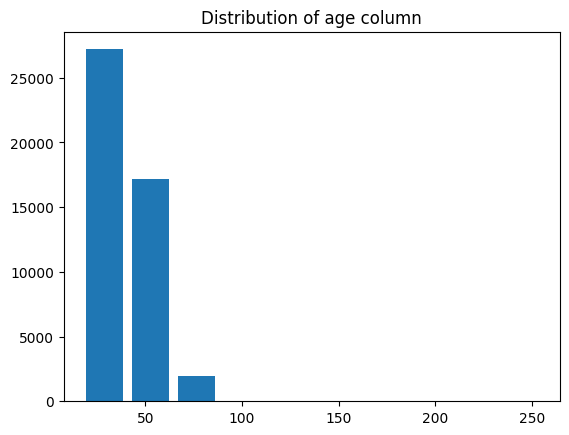

In [6]:
# checking the distribution of age column
plt.hist(data['age'], rwidth=0.8)
plt.title('Distribution of age column')
plt.show() # displays all the open graphs

In [7]:
data['age'] = data['age'].fillna(
    data['age'].median())  # since it is right skewed we use median

data.isna().sum()

,0
age,0
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


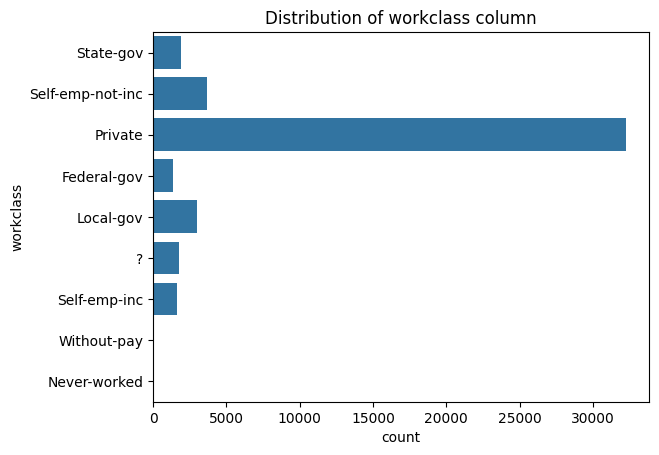

In [8]:
# checking the distribution of workclass column
sns.countplot(y=data['workclass'])
plt.title('Distribution of workclass column')
plt.show() # displays all the open graphs

In [9]:
data['workclass'] = data['workclass'].fillna(
    data['workclass'].mode()[0])  # Since it is categorical, we fill missing values with the mode

data.isna().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


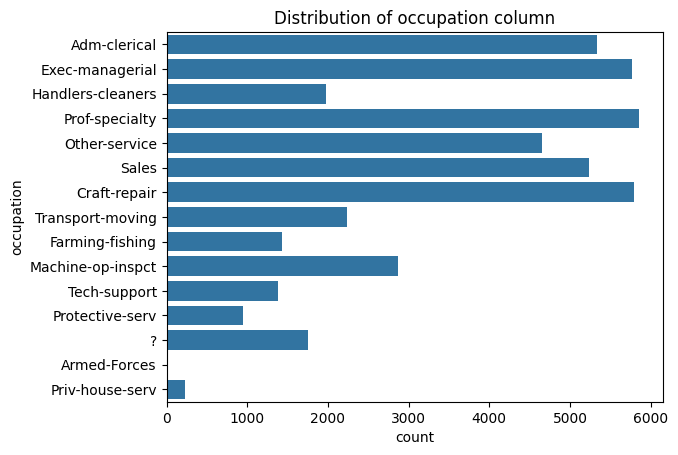

In [10]:
# checking the distribution of occupation column
sns.countplot(y=data['occupation'])
plt.title('Distribution of occupation column')
plt.show() # displays all the open graphs

In [11]:
data['occupation'] = data['occupation'].fillna(
    data['occupation'].mode()[0])  # Since it is categorical, we fill missing values with the mode

data.isna().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


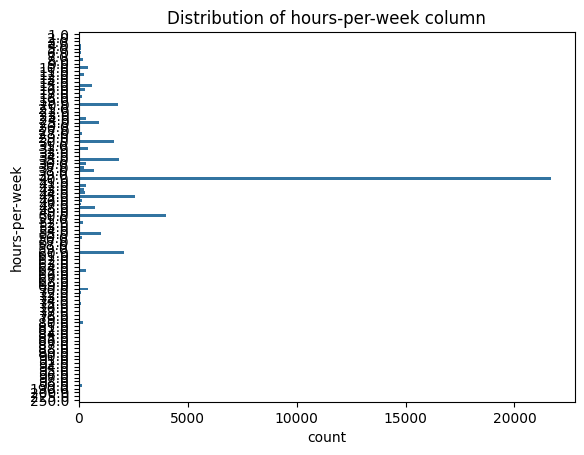

In [12]:
# checking the distribution of hours-per-week column
sns.countplot(y=data['hours-per-week'])
plt.title('Distribution of hours-per-week column')
plt.show() # displays all the open graphs

In [13]:
data['hours-per-week'] = data['hours-per-week'].fillna(
    data['hours-per-week'].mode()[0])  # Since it is categorical, we fill missing values with the mode

data.isna().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


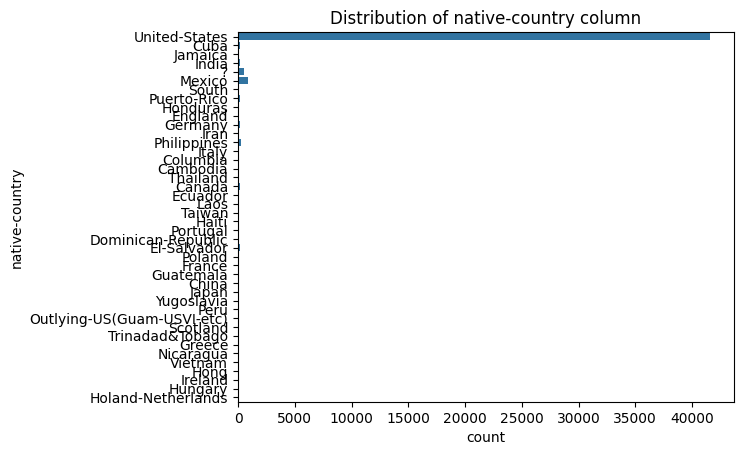

In [14]:
# checking the distribution of native-country column
sns.countplot(y=data['native-country'])
plt.title('Distribution of native-country column')
plt.show() # displays all the open graphs

In [15]:
data['native-country'] = data['native-country'].fillna(
    data['native-country'].mode()[0])  # Since it is categorical, we use mode instead of median

data.isna().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


#Detecting Outliers

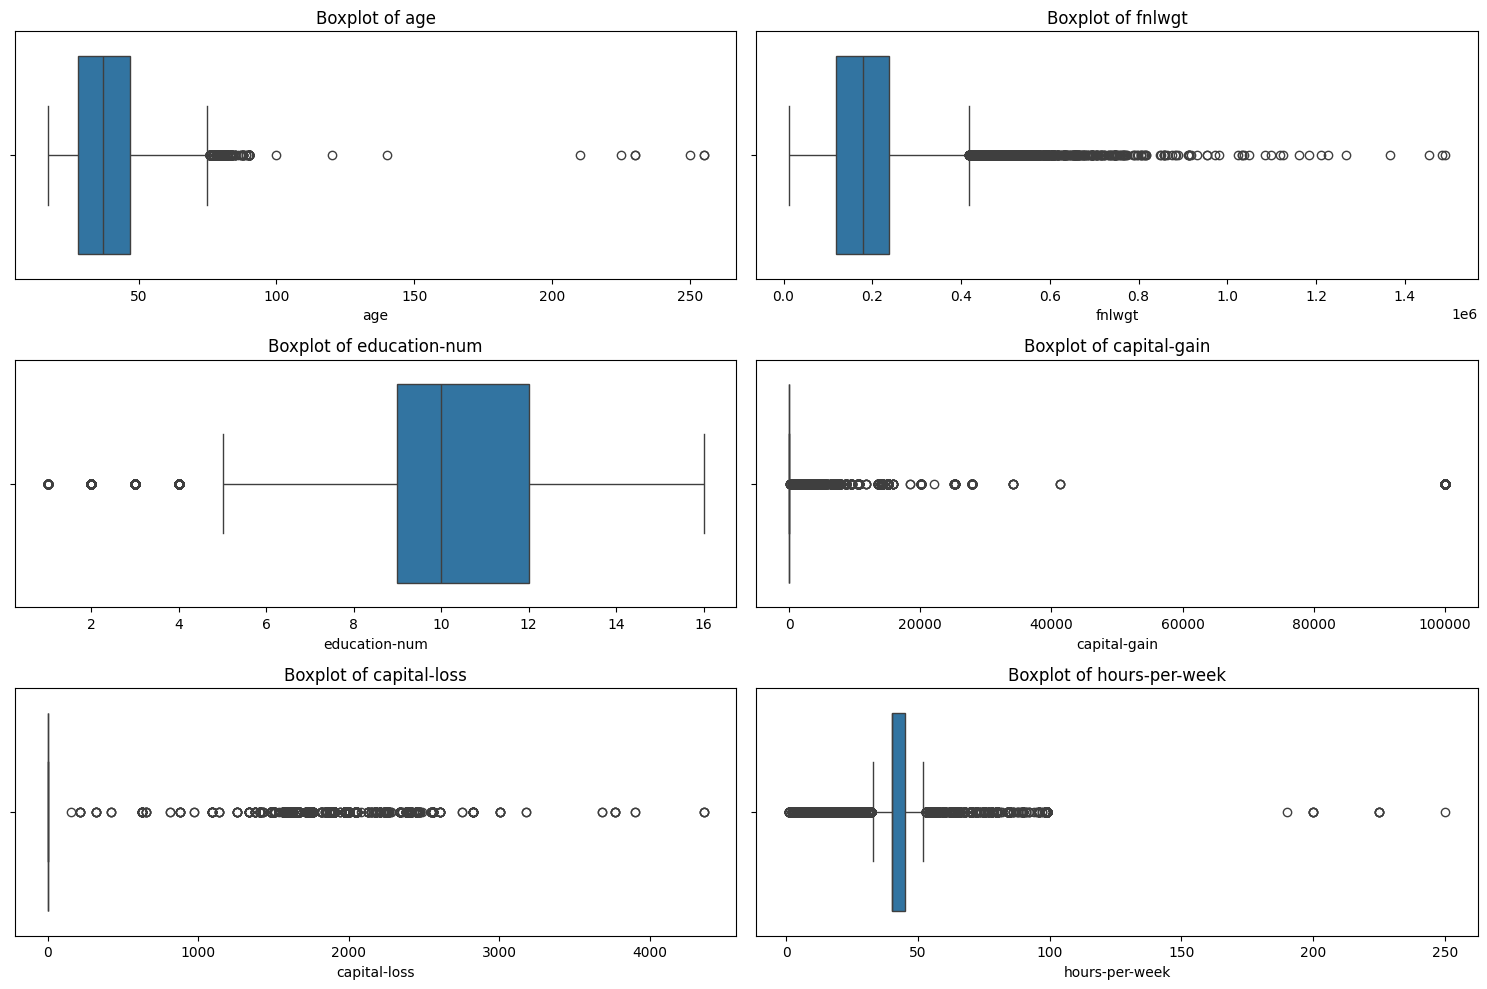

In [16]:
# Define numerical columns
num_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# Plotting boxplots for each numerical variable to detect outliers
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

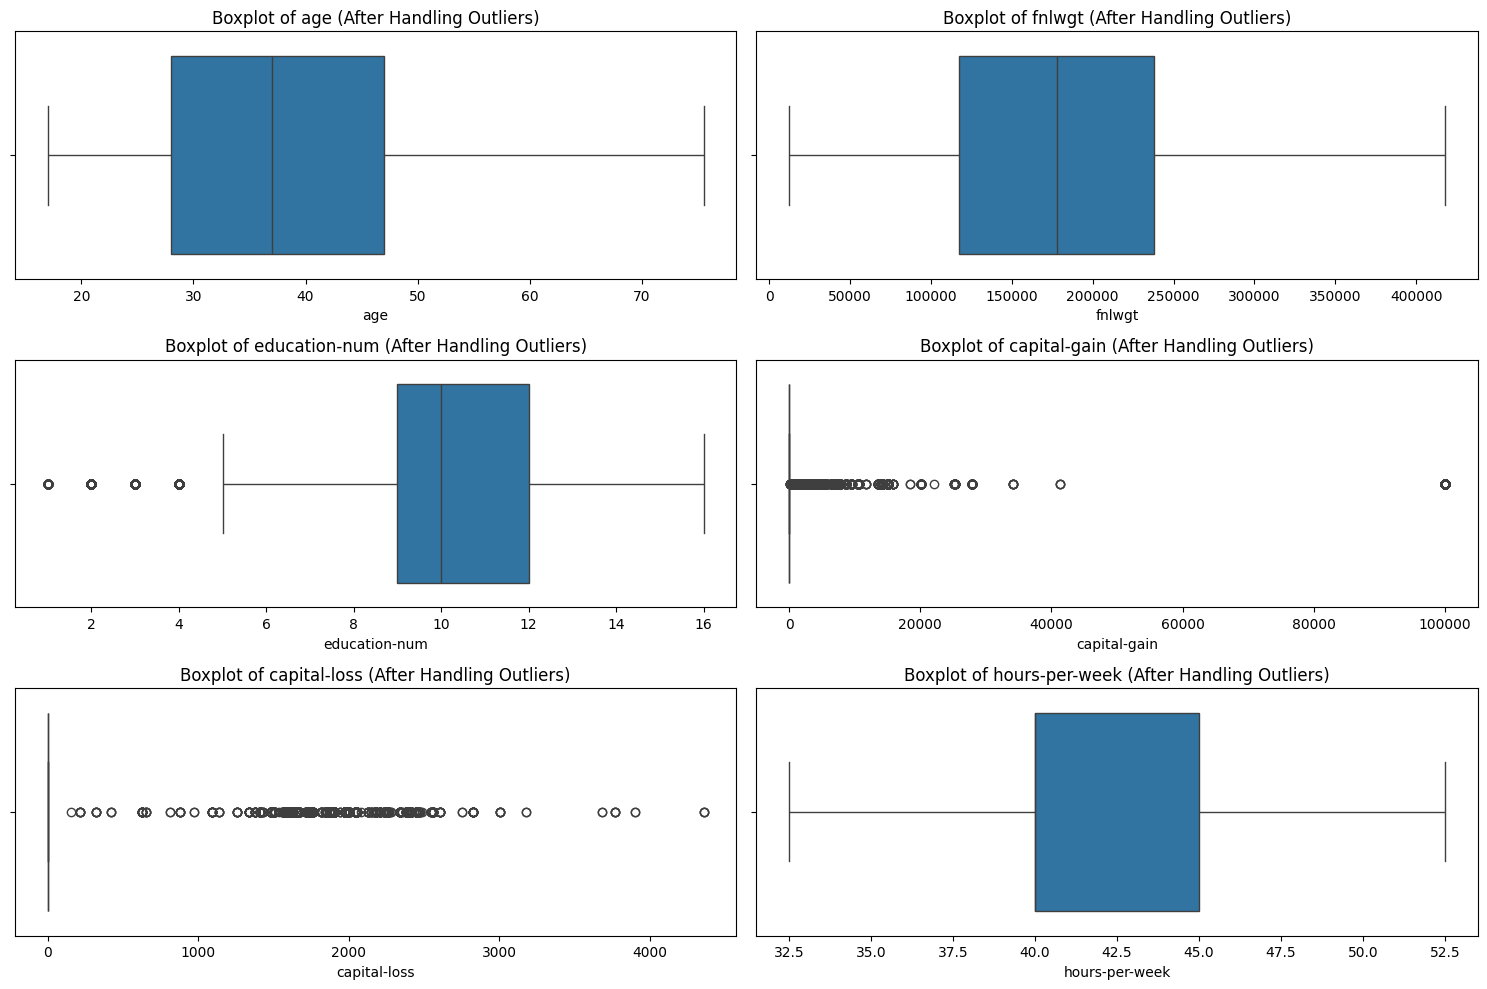

In [17]:
# Capping extreme outliers using IQR method for selected columns
for col in ['age', 'fnlwgt', 'hours-per-week']:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Cap the outliers to lower and upper limits
    data[col] = np.clip(data[col], lower_limit, upper_limit)

# Re-plotting boxplots to verify
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot of {col} (After Handling Outliers)')

plt.tight_layout()
plt.show()

### Data Preprocessing for K-Means Clustering

In [18]:
from sklearn.preprocessing import StandardScaler

# 1. Separate features and target (income) since income is our label
X = data.drop(columns=['income'])

# 2. Convert categorical columns to numeric using One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Standardize all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# 4. Convert back to DataFrame for verification
X_scaled_df = pd.DataFrame(X_scaled, columns=X_encoded.columns)
display(X_scaled_df.head())

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,0.035311,-1.146097,1.136512,0.146932,-0.217127,-0.187236,-0.168343,-0.254588,-0.013576,-1.638111,...,-0.036785,-0.059966,-0.02024,-0.046637,-0.035362,-0.024374,-0.02263,0.319150,-0.041258,-0.021705
1,0.864184,-1.085307,1.136512,-0.144804,-0.217127,-1.430298,-0.168343,-0.254588,-0.013576,-1.638111,...,-0.036785,-0.059966,-0.02024,-0.046637,-0.035362,-0.024374,-0.02263,0.319150,-0.041258,-0.021705
2,-0.040041,0.302906,-0.419335,-0.144804,-0.217127,-0.187236,-0.168343,-0.254588,-0.013576,0.610459,...,-0.036785,-0.059966,-0.02024,-0.046637,-0.035362,-0.024374,-0.02263,0.319150,-0.041258,-0.021705
3,1.090241,0.503005,-1.197259,-0.144804,-0.217127,-0.187236,-0.168343,-0.254588,-0.013576,0.610459,...,-0.036785,-0.059966,-0.02024,-0.046637,-0.035362,-0.024374,-0.02263,0.319150,-0.041258,-0.021705
4,-0.793562,1.590706,1.136512,-0.144804,-0.217127,-0.187236,-0.168343,-0.254588,-0.013576,0.610459,...,-0.036785,-0.059966,-0.02024,-0.046637,-0.035362,-0.024374,-0.02263,-3.133324,-0.041258,-0.021705


### K-Means Clustering
Now we will find the optimal number of clusters using the Elbow Method and fit the K-Means model.

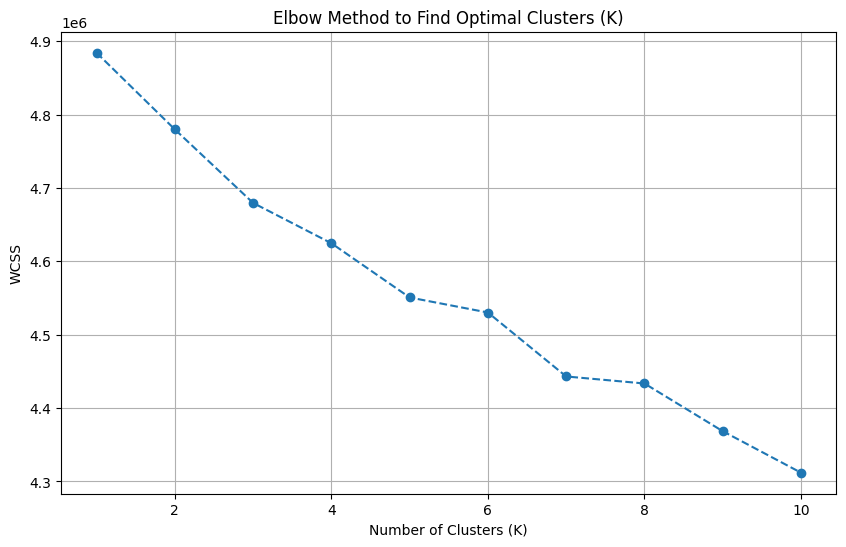

In [19]:
from sklearn.cluster import KMeans

# Calculate WCSS (Within-Cluster Sum of Squares) for a range of clusters
wcss = []
cluster_range = range(1, 11)

for k in cluster_range:
    # Using a fast/lite configuration for performance
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=5, max_iter=300)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve to find the optimal 'K'
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method to Find Optimal Clusters (K)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

### Fitting K-Means Model ($K=4$) and Profiling Clusters

In [20]:
from sklearn.cluster import KMeans

# Fit the final KMeans model
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X_scaled)

# Count the number of records in each cluster
print("Cluster Distribution:")
print(data['Cluster'].value_value_counts() if hasattr(data['Cluster'], 'value_value_counts') else data['Cluster'].value_counts())

# Analyze numerical columns by cluster
print("\nCluster Numerical Characteristics (Mean values):")
print(data.groupby('Cluster')[num_cols].mean())

Cluster Distribution:
Cluster
0    22193
1    21125
3     4690
2      834
Name: count, dtype: int64

Cluster Numerical Characteristics (Mean values):
               age         fnlwgt  education-num  capital-gain  capital-loss  \
Cluster                                                                        
0        34.034628  185260.787039       9.857793    358.067048     55.759969   
1        43.177325  180776.251373      10.251124   1574.720899    121.054675   
2        44.748201  185023.523082      15.000000  10586.467626    232.628297   
3        37.777932  221226.930490       9.465885    567.621748     60.770789   

         hours-per-week  
Cluster                  
0             39.662168  
1             42.822178  
2             44.870504  
3             39.785288  


In [22]:
from sklearn.cluster import AgglomerativeClustering

sample_indices = data.sample(n=5000, random_state=42).index
X_sample = X_scaled[data.index.get_indexer(sample_indices)]

agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X_sample)
print(pd.Series(agg_labels).value_counts())

2    4634
0     361
1       5
Name: count, dtype: int64


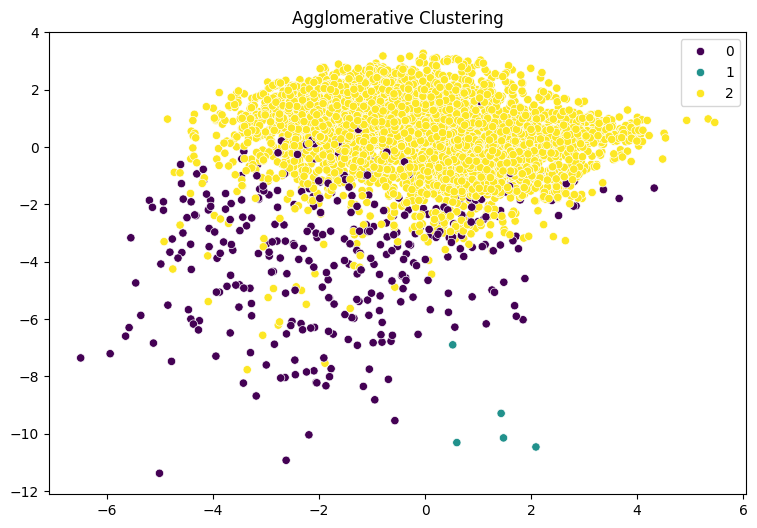

In [24]:
from sklearn.decomposition import PCA

X_sample_pca = PCA(n_components=2).fit_transform(X_sample)
plt.figure(figsize=(9, 6))

sns.scatterplot(x=X_sample_pca[:, 0], y=X_sample_pca[:, 1], hue=agg_labels, palette='viridis')
plt.title('Agglomerative Clustering')
plt.show()